### Import libraries

In [3]:
%pip install shap

   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 751.9/751.9 kB 7.9 MB/s eta 0:00:00
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
    --------------------------------------- 0.3/12.6 MB ? eta -:--:--
   -- ------------------------------------- 0.8/12.6 MB 1.3 MB/s eta 0:00:09
   ------- -------------------------------- 2.4/12.6 MB 3.6 MB/s eta 0:00:03
   -------------- ------------------------- 4.7/12.6 MB 5.6 MB/s eta 0:00:02
   ----------------------- ---------------- 7.3/12.6 MB 7.2 MB/s eta 0:00:01
   ------------------------------ --------- 9.7/12.6 MB 7.8 MB/s eta 0:00:01
   ------------------------------------- -- 11.8/12.6 MB 8.2 MB/s eta 0:00:01
   ---------------------------------------- 12.6/12.6 MB 8.0 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
Note: you may nee

  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
contourpy 1.2.0 requires numpy<2.0,>=1.20, but you have numpy 2.2.6 which is incompatible.
gensim 4.3.3 requires numpy<2.0,>=1.18.5, but you have numpy 2.2.6 which is incompatible.
gensim 4.3.3 requires scipy<1.14.0,>=1.7.0, but you have scipy 1.14.1 which is incompatible.
numba 0.60.0 requires numpy<2.1,>=1.22, but you have numpy 2.2.6 which is incompatible.


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap
import joblib

from pathlib import Path

print("SHAP version:", shap.__version__)
print("Libraries imported successfully.")

SHAP version: 0.54.1
Libraries imported successfully.


### Load the saved model and test data

In [6]:
from pathlib import Path
import joblib
import pandas as pd

# Define project paths
model_dir = Path("../models")
output_dir = Path("../reports/shap")
output_dir.mkdir(parents=True, exist_ok=True)

model_path = model_dir / "churniq_lightgbm_pipeline.joblib"
test_path = model_dir / "X_test.csv"
target_path = model_dir / "y_test.csv"

# Check required files
required_files = [model_path, test_path, target_path]

for file_path in required_files:
    if not file_path.is_file():
        raise FileNotFoundError(
            f"File not found: {file_path.resolve()}\n"
            "Check your project folder structure and file names."
        )

# Load saved pipeline and test data
lightgbm_pipeline = joblib.load(model_path)
X_test = pd.read_csv(test_path)
y_test = pd.read_csv(target_path).iloc[:, 0]

# Verify loaded data
print("Model loaded successfully.")
print("Test features shape:", X_test.shape)
print("Test target shape:", y_test.shape)

# Check consistency
assert len(X_test) == len(y_test), (
    "Mismatch: X_test and y_test have different numbers of rows."
)

print("Test data validation successful.")
print("SHAP output directory:", output_dir.resolve())

Model loaded successfully.
Test features shape: (1409, 8)
Test target shape: (1409,)
Test data validation successful.
SHAP output directory: C:\CHURNIQ\REPORTS\shap


### Prepare features for SHAP

In [7]:
# Extract the fitted preprocessing and LightGBM steps
preprocessor = lightgbm_pipeline.named_steps["preprocessor"]
lgbm_model = lightgbm_pipeline.named_steps["model"]

# Transform test data using the fitted preprocessor
X_test_transformed = preprocessor.transform(X_test)

# Get feature names after one-hot encoding
feature_names = preprocessor.get_feature_names_out()

# Convert sparse matrix to dense if needed
if hasattr(X_test_transformed, "toarray"):
    X_test_transformed = X_test_transformed.toarray()

X_test_transformed = np.asarray(X_test_transformed)

print("Transformed test shape:", X_test_transformed.shape)
print("Number of transformed features:", len(feature_names))
print("LightGBM model ready for SHAP.")

Transformed test shape: (1409, 8)
Number of transformed features: 8
LightGBM model ready for SHAP.


### Calculate SHAP values

In [9]:
import warnings

warnings.filterwarnings(
    "ignore",
    message="LightGBM binary classifier with TreeExplainer shap values output has changed.*",
    category=UserWarning
)

In [10]:
# Select a sample of the held-out test set
sample_size = min(1000, len(X_test_transformed))

X_shap = X_test_transformed[:sample_size]

# Explain the trained LightGBM model
explainer = shap.TreeExplainer(lgbm_model)
shap_values = explainer.shap_values(X_shap)

# Handle SHAP output formats across versions
if isinstance(shap_values, list):
    # Binary classifier: class 1 means churn
    shap_values = shap_values[1]
else:
    shap_values = np.asarray(shap_values)

    if shap_values.ndim == 3:
        shap_values = shap_values[:, :, 1]

# Create a SHAP Explanation object for plotting
base_value = np.asarray(explainer.expected_value).reshape(-1)

if len(base_value) > 1:
    base_value = base_value[1]
else:
    base_value = base_value[0]

shap_explanation = shap.Explanation(
    values=shap_values,
    base_values=np.full(sample_size, base_value),
    data=X_shap,
    feature_names=feature_names
)

print("SHAP calculation completed.")
print("SHAP values shape:", shap_values.shape)

SHAP calculation completed.
SHAP values shape: (1000, 8)


### Global feature importance

,feature,mean_absolute_shap
0,numerical__tenure_months,1.285912
3,numerical__avg_historical_monthly_charge,1.107036
5,numerical__charge_difference_pct,0.303861
4,numerical__charge_difference,0.232977
1,numerical__is_new_customer,0.003763
2,numerical__is_long_term_customer,0.001874
6,numerical__is_month_to_month,0.000000
7,numerical__is_long_contract,0.000000


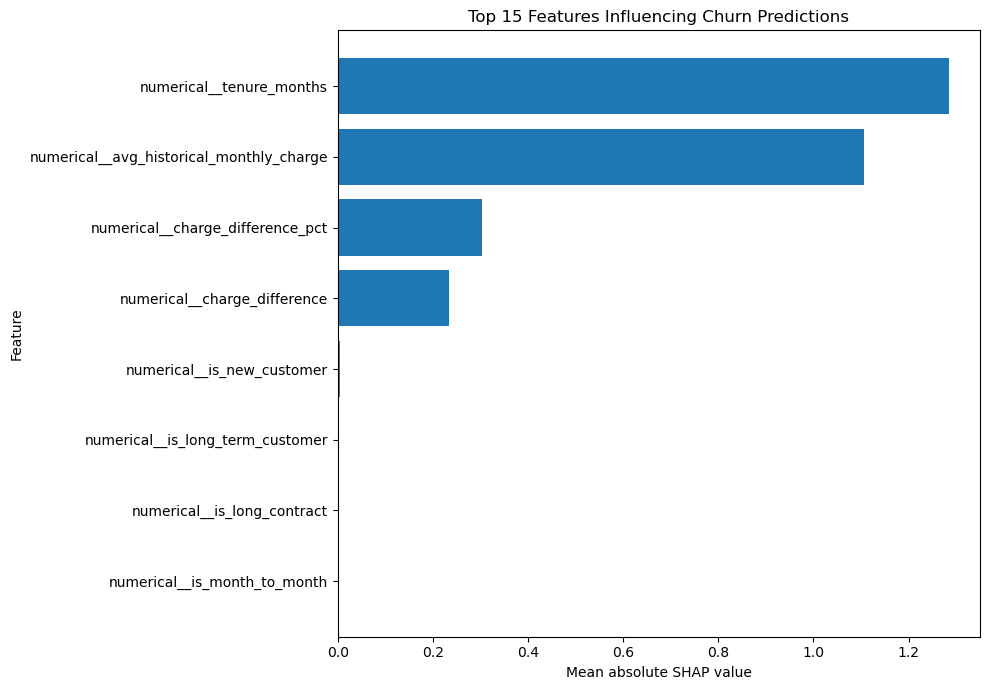

In [11]:
shap_importance = pd.DataFrame({
    "feature": feature_names,
    "mean_absolute_shap": np.abs(shap_values).mean(axis=0)
}).sort_values(
    "mean_absolute_shap",
    ascending=False
)

display(shap_importance.head(15))

# Plot top 15 features
top_features = shap_importance.head(15).sort_values(
    "mean_absolute_shap"
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_features["feature"],
    top_features["mean_absolute_shap"]
)
plt.xlabel("Mean absolute SHAP value")
plt.ylabel("Feature")
plt.title("Top 15 Features Influencing Churn Predictions")
plt.tight_layout()

plt.savefig(
    output_dir / "shap_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

shap_importance.to_csv(
    output_dir / "shap_feature_importance.csv",
    index=False
)

### SHAP summary plot

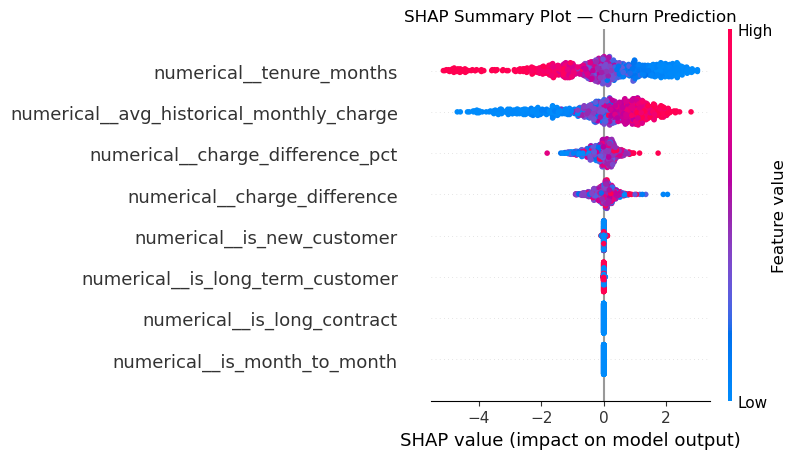

In [12]:
plt.figure(figsize=(10, 7))

shap.plots.beeswarm(
    shap_explanation,
    max_display=15,
    show=False
)

plt.title("SHAP Summary Plot — Churn Prediction")
plt.tight_layout()

plt.savefig(
    output_dir / "shap_summary_plot.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Explain one customer's prediction

In [15]:
import os

# Limit joblib to 4 logical CPU cores
os.environ["LOKY_MAX_CPU_COUNT"] = "4"

print("CPU limit configured successfully.")

CPU limit configured successfully.


Test customer index: 0
Actual churn label: 0
Predicted churn probability: 38.81%


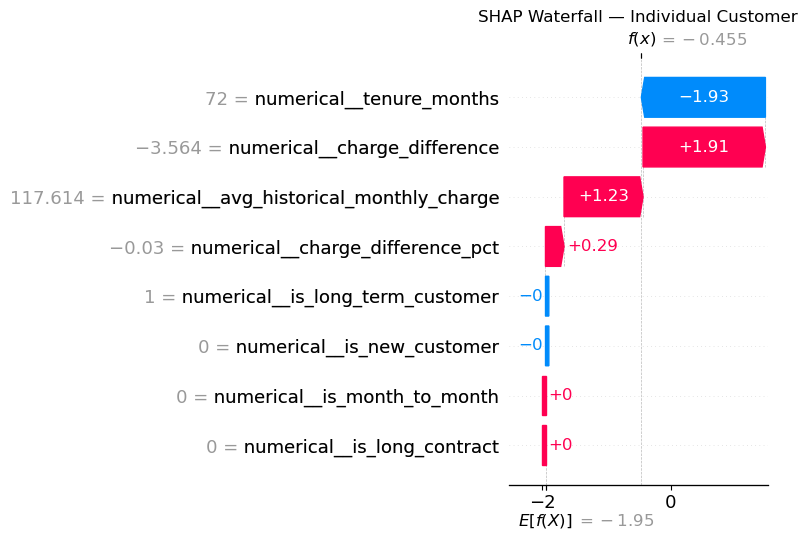

In [16]:
customer_index = 0

# Predict churn probability using the original pipeline
customer_features = X_test.iloc[[customer_index]]
churn_probability = lightgbm_pipeline.predict_proba(
    customer_features
)[0, 1]

actual_churn = y_test.iloc[customer_index]

print("Test customer index:", customer_index)
print("Actual churn label:", actual_churn)
print(f"Predicted churn probability: {churn_probability:.2%}")

# Explain this customer's prediction
shap.plots.waterfall(
    shap_explanation[customer_index],
    max_display=15,
    show=False
)

plt.title("SHAP Waterfall — Individual Customer")
plt.tight_layout()

plt.savefig(
    output_dir / "shap_individual_customer.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Save customer-level SHAP contributions

In [17]:
customer_shap = pd.DataFrame({
    "feature": feature_names,
    "feature_value": X_shap[customer_index],
    "shap_value": shap_values[customer_index]
})

customer_shap["absolute_shap"] = (
    customer_shap["shap_value"].abs()
)

customer_shap = customer_shap.sort_values(
    "absolute_shap",
    ascending=False
)

display(customer_shap.head(15))

customer_shap.to_csv(
    output_dir / "shap_individual_customer_values.csv",
    index=False
)

print("Individual explanation saved.")

,feature,feature_value,shap_value,absolute_shap
0,numerical__tenure_months,72.000000,-1.933877,1.933877
4,numerical__charge_difference,-3.563889,1.907670,1.907670
3,numerical__avg_historical_monthly_charge,117.613889,1.232231,1.232231
5,numerical__charge_difference_pct,-0.030302,0.289030,0.289030
2,numerical__is_long_term_customer,1.000000,-0.000514,0.000514
1,numerical__is_new_customer,0.000000,-0.000116,0.000116
6,numerical__is_month_to_month,0.000000,0.000000,0.000000
7,numerical__is_long_contract,0.000000,0.000000,0.000000


Individual explanation saved.


### Save SHAP summary results

In [18]:
summary = pd.DataFrame([{
    "customers_explained": sample_size,
    "features_explained": len(feature_names),
    "top_feature": shap_importance.iloc[0]["feature"],
    "top_feature_mean_absolute_shap":
        shap_importance.iloc[0]["mean_absolute_shap"]
}])

display(summary)

summary.to_csv(
    output_dir / "shap_summary_results.csv",
    index=False
)

print("All SHAP results saved to:", output_dir.resolve())

,customers_explained,features_explained,top_feature,top_feature_mean_absolute_shap
0,1000,8,numerical__tenure_months,1.285912


All SHAP results saved to: C:\CHURNIQ\REPORTS\shap


### save all shap to csv

In [19]:
from pathlib import Path
import pandas as pd
import numpy as np

# Create output folder
output_dir = Path("../reports/shap")
output_dir.mkdir(parents=True, exist_ok=True)

# 1. Save global feature importance
shap_importance.to_csv(
    output_dir / "shap_feature_importance.csv",
    index=False
)

# 2. Save individual customer SHAP values
customer_shap.to_csv(
    output_dir / "shap_individual_customer_values.csv",
    index=False
)

# 3. Save summary results
summary.to_csv(
    output_dir / "shap_summary_results.csv",
    index=False
)

# 4. Save SHAP values for all sampled test customers
shap_results = pd.DataFrame(
    shap_values,
    columns=feature_names
)

shap_results.insert(
    0,
    "customer_sample_index",
    range(len(shap_results))
)

shap_results.to_csv(
    output_dir / "shap_all_customer_values.csv",
    index=False
)

# 5. Verify saved files
print("SHAP CSV files saved successfully!\n")

for file_path in sorted(output_dir.glob("*.csv")):
    print(f"{file_path.name} | {file_path.stat().st_size:,} bytes")

SHAP CSV files saved successfully!

shap_all_customer_values.csv | 137,121 bytes
shap_feature_importance.csv | 410 bytes
shap_individual_customer_values.csv | 634 bytes
shap_summary_results.csv | 135 bytes


In [1]:
from pathlib import Path

shap_dir = Path("../reports/shap")

if shap_dir.exists():
    print("Files currently saved in reports/shap:")

    for file in sorted(shap_dir.iterdir()):
        if file.is_file():
            print("-", file.name)
else:
    print("SHAP output directory does not exist yet.")

Files currently saved in reports/shap:
- shap_all_customer_values.csv
- shap_feature_importance.csv
- shap_feature_importance.png
- shap_individual_customer.png
- shap_individual_customer_values.csv
- shap_summary_plot.png
- shap_summary_results.csv
